# Support Vector Machine — Hyperparameter Tuning

Loads the shared train/val/test splits saved by `data_eda.ipynb`, vectorizes with TF-IDF (update the
config below if `bow_vs_tfidf.ipynb` found a better one than the default), then searches both
**linear** (`LinearSVC`) and **non-linear** (`SVC` with RBF/polynomial kernels) SVM hyperparameters.
Every candidate combination is logged to MLflow, and the best model overall gets registered.

**Note on kernel choice:** this notebook previously used `LinearSVC` only, on the reasoning that RBF
kernels don't scale to high-dimensional sparse TF-IDF vectors. That reasoning was never actually
measured against this dataset — after the switch to SEntFiN (7,094 train rows, much smaller than the
17k+ this notebook used to run against), a quick benchmark shows `SVC(kernel="rbf")` and
`SVC(kernel="poly")` both fit in ~10 seconds here, so they're now included as a real comparison
rather than assumed away.

Run `data_eda.ipynb` first — this notebook depends on the CSVs it saves.

In [1]:
# ── libraries ──
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import SGDClassifier

import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── config + load the shared splits ──
MODEL_NAME = "SVM"
SEED = 42

DATA_DIR = "../data/processed"
RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MLFLOW_EXPERIMENT = "IndianFinSentiment_ClassicalML"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

Train: 7094  |  Val: 946  |  Test: 1419


## Vectorize with TF-IDF

**Update these two values** if `bow_vs_tfidf.ipynb` found a better config than this default.

In [3]:
TFIDF_MAX_FEATURES = 15_000
TFIDF_NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=TFIDF_NGRAM_RANGE, min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train, y_val, y_test = train_df["label_id"], val_df["label_id"], test_df["label_id"]
print(f"TF-IDF matrix shape: {X_train.shape}")

TF-IDF matrix shape: (7094, 11720)


In [4]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path

## Broader hyperparameter search

The old version only searched `C` (4 values) — 4 candidates x 3-fold CV = 12 fits. This version
adds `loss` (`"hinge"` = the classic SVM loss, `"squared_hinge"` = LinearSVC's default, smoother
and often a bit more accurate) and `class_weight` (`None` vs `"balanced"`, for the mild class
imbalance), searched with `RandomizedSearchCV` and `verbose=2` so every fold's fit prints as it
happens.

In [5]:
model = LinearSVC(max_iter=5000, dual="auto", random_state=SEED)

param_distributions = {
    "C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30],
    "loss": ["hinge", "squared_hinge"],
    "class_weight": [None, "balanced"],
}

start = time.time()
random_search = RandomizedSearchCV(
    model, param_distributions, n_iter=30, cv=5, scoring="f1_weighted",
    n_jobs=-1, random_state=SEED, verbose=2,
)
random_search.fit(X_train, y_train)
search_time = time.time() - start

n_combos = len(random_search.cv_results_["params"])
print(f"\nRandom search done in {search_time:.1f}s — tried {n_combos} combinations x 5-fold CV = {n_combos * 5} fits")
print(f"Best params: {random_search.best_params_}")
print(f"Best CV F1 (weighted): {random_search.best_score_:.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits



Random search done in 9.3s — tried 30 combinations x 5-fold CV = 150 fits
Best params: {'loss': 'hinge', 'class_weight': 'balanced', 'C': 1}
Best CV F1 (weighted): 0.8211


## Log every candidate combination to MLflow

In [6]:
for params, mean_score, std_score in zip(
    random_search.cv_results_["params"],
    random_search.cv_results_["mean_test_score"],
    random_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))

print(f"Logged {len(random_search.cv_results_['params'])} candidate runs to MLflow.")

Logged 30 candidate runs to MLflow.


## Overfitting check: train vs val vs test (linear CV-best model)

In [7]:
cv_best_model = random_search.best_estimator_
train_metrics_cv = evaluate(y_train, cv_best_model.predict(X_train))
val_metrics_cv = evaluate(y_val, cv_best_model.predict(X_val))
test_metrics_cv = evaluate(y_test, cv_best_model.predict(X_test))

print(f"{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_cv), ("Val", val_metrics_cv), ("Test", test_metrics_cv)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

gap = train_metrics_cv["f1_weighted"] - val_metrics_cv["f1_weighted"]
print(f"\nTrain-Val F1 gap: {gap:.4f} (large positive gap = overfitting)")

Split      Accuracy  F1 (weighted)
Train        0.9626         0.9627
Val          0.8224         0.8225
Test         0.8111         0.8112

Train-Val F1 gap: 0.1402 (large positive gap = overfitting)


## Epoch-based training (SGD, hinge loss) with early stopping

`LinearSVC` solves the SVM optimization problem directly (a QP-style solver) and doesn't expose a
training curve. `SGDClassifier(loss="hinge")` is the same linear SVM objective trained via
stochastic gradient descent — same `partial_fit()`-per-epoch pattern used for logistic regression
and the deep learning notebooks, giving a real train/val curve and early stopping.

 Epoch | train_acc  train_f1 |   val_acc    val_f1 |  test_acc   test_f1
----------------------------------------------------------------------------
     1 |    0.9426    0.9426 |    0.7970    0.7971 |    0.7914    0.7915
     2 |    0.9539    0.9539 |    0.8161    0.8161 |    0.8055    0.8055
     3 |    0.9586    0.9586 |    0.8140    0.8139 |    0.8069    0.8069
     4 |    0.9602    0.9603 |    0.8266    0.8267 |    0.8062    0.8062
     5 |    0.9608    0.9608 |    0.8214    0.8215 |    0.8125    0.8126


     6 |    0.9625    0.9625 |    0.8203    0.8204 |    0.8090    0.8091
     7 |    0.9617    0.9617 |    0.8203    0.8202 |    0.8097    0.8097


     8 |    0.9614    0.9614 |    0.8224    0.8224 |    0.8097    0.8097


     9 |    0.9625    0.9625 |    0.8182    0.8182 |    0.8118    0.8119
    10 |    0.9618    0.9618 |    0.8214    0.8213 |    0.8104    0.8105
    11 |    0.9628    0.9628 |    0.8224    0.8224 |    0.8097    0.8098
    12 |    0.9621    0.9621 |    0.8214    0.8214 |    0.8104    0.8105
    13 |    0.9625    0.9625 |    0.8224    0.8224 |    0.8104    0.8104
    14 |    0.9621    0.9621 |    0.8214    0.8214 |    0.8111    0.8112

Early stopping at epoch 14 (best was epoch 4, val_f1=0.8267)


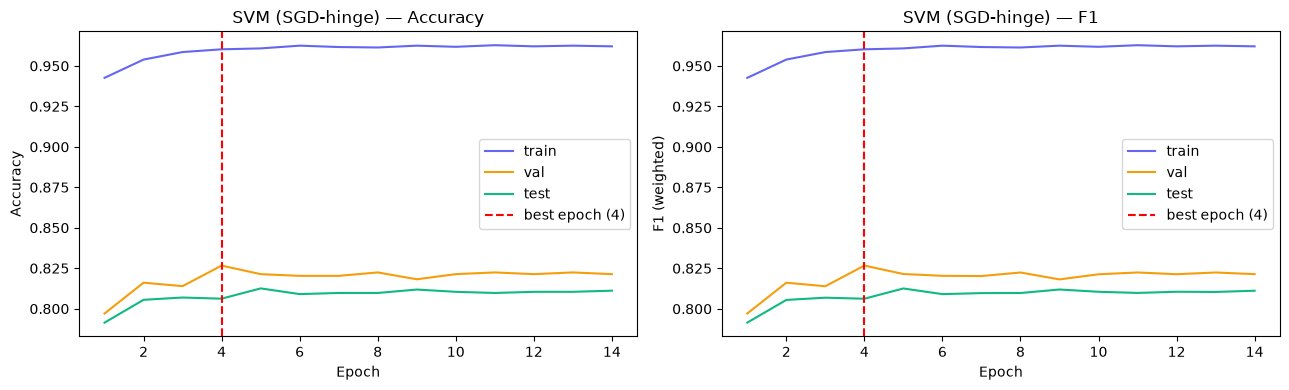

In [8]:
best_params = random_search.best_params_
sgd_alpha = 1.0 / (best_params["C"] * X_train.shape[0])

MAX_EPOCHS = 100
PATIENCE = 10

classes = np.array(sorted(y_train.unique()))

# SGDClassifier.partial_fit() can't accept class_weight="balanced" directly — it needs the full
# label distribution upfront to compute balanced weights, which isn't available incrementally.
if best_params["class_weight"] == "balanced":
    from sklearn.utils.class_weight import compute_class_weight
    weights = compute_class_weight("balanced", classes=classes, y=y_train)
    sgd_class_weight = dict(zip(classes.tolist(), weights.tolist()))
else:
    sgd_class_weight = None

sgd_model = SGDClassifier(
    loss="hinge", penalty="l2", alpha=sgd_alpha,
    class_weight=sgd_class_weight, random_state=SEED,
)

y_train_arr, y_val_arr, y_test_arr = y_train.values, y_val.values, y_test.values
n_train = X_train.shape[0]
rng = np.random.RandomState(SEED)

best_val_f1, best_epoch, epochs_no_improve = -1.0, 0, 0
best_coef, best_intercept = None, None
history = []

print(f"{'Epoch':>6} | {'train_acc':>9} {'train_f1':>9} | {'val_acc':>9} {'val_f1':>9} | {'test_acc':>9} {'test_f1':>9}")
print("-" * 76)
for epoch in range(1, MAX_EPOCHS + 1):
    perm = rng.permutation(n_train)
    sgd_model.partial_fit(X_train[perm], y_train_arr[perm], classes=classes)

    train_pred = sgd_model.predict(X_train)
    val_pred = sgd_model.predict(X_val)
    test_pred = sgd_model.predict(X_test)   # informational only — never used to pick the epoch

    train_acc = accuracy_score(y_train_arr, train_pred)
    train_f1 = f1_score(y_train_arr, train_pred, average="weighted")
    val_acc = accuracy_score(y_val_arr, val_pred)
    val_f1 = f1_score(y_val_arr, val_pred, average="weighted")
    test_acc = accuracy_score(y_test_arr, test_pred)
    test_f1 = f1_score(y_test_arr, test_pred, average="weighted")
    history.append({
        "epoch": epoch, "train_acc": train_acc, "train_f1": train_f1,
        "val_acc": val_acc, "val_f1": val_f1, "test_acc": test_acc, "test_f1": test_f1,
    })

    print(f"{epoch:>6} | {train_acc:>9.4f} {train_f1:>9.4f} | {val_acc:>9.4f} {val_f1:>9.4f} | "
          f"{test_acc:>9.4f} {test_f1:>9.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        best_coef, best_intercept = sgd_model.coef_.copy(), sgd_model.intercept_.copy()
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} (best was epoch {best_epoch}, val_f1={best_val_f1:.4f})")
            break

sgd_model.coef_, sgd_model.intercept_ = best_coef, best_intercept
history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_acc"], label="train", color="#6366f1")
axes[0].plot(history_df["epoch"], history_df["val_acc"], label="val", color="#f59e0b")
axes[0].plot(history_df["epoch"], history_df["test_acc"], label="test", color="#10b981")
axes[0].axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].set_title(f"{MODEL_NAME} (SGD-hinge) — Accuracy"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_f1"], label="train", color="#6366f1")
axes[1].plot(history_df["epoch"], history_df["val_f1"], label="val", color="#f59e0b")
axes[1].plot(history_df["epoch"], history_df["test_f1"], label="test", color="#10b981")
axes[1].axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (weighted)"); axes[1].set_title(f"{MODEL_NAME} (SGD-hinge) — F1"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/training_curve_{MODEL_NAME.lower()}.png", dpi=120, bbox_inches="tight")
plt.show()

## Non-linear SVM comparison (RBF & polynomial kernels)

`SVC(kernel="rbf")` and `SVC(kernel="poly")` solve a genuinely different, non-linear decision
boundary — worth checking directly rather than assuming linear is best. Both kernels don't
support `partial_fit`, so there's no epoch-based training story for them (their solver is a
single-shot QP optimization, not iterative gradient descent) — this section is CV search only.
`cv=3` (not 5) here since each kernel-SVM fit is slower (~10s) than the linear variants.

In [9]:
kernel_model = SVC(random_state=SEED)

# Two separate param spaces (one per kernel) — 'degree' only makes sense for "poly", and mixing
# them into one dict would waste search budget sampling a param the kernel ignores.
kernel_param_distributions = [
    {"kernel": ["rbf"], "C": [0.1, 1, 3, 10, 30], "gamma": ["scale", "auto", 0.01, 0.1],
     "class_weight": [None, "balanced"]},
    {"kernel": ["poly"], "C": [0.1, 1, 3, 10], "gamma": ["scale", "auto"],
     "degree": [2, 3, 4], "class_weight": [None, "balanced"]},
]

start = time.time()
kernel_search = RandomizedSearchCV(
    kernel_model, kernel_param_distributions, n_iter=16, cv=3, scoring="f1_weighted",
    n_jobs=-1, random_state=SEED, verbose=2,
)
kernel_search.fit(X_train, y_train)
kernel_search_time = time.time() - start

n_combos = len(kernel_search.cv_results_["params"])
print(f"\nKernel search done in {kernel_search_time:.1f}s — tried {n_combos} combinations x 3-fold CV = {n_combos * 3} fits")
print(f"Best params: {kernel_search.best_params_}")
print(f"Best CV F1 (weighted): {kernel_search.best_score_:.4f}")

kernel_best_model = kernel_search.best_estimator_
train_metrics_kernel = evaluate(y_train, kernel_best_model.predict(X_train))
val_metrics_kernel = evaluate(y_val, kernel_best_model.predict(X_val))
test_metrics_kernel = evaluate(y_test, kernel_best_model.predict(X_test))

print(f"\n{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_kernel), ("Val", val_metrics_kernel), ("Test", test_metrics_kernel)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")
print(f"\nTrain-Val F1 gap: {train_metrics_kernel['f1_weighted'] - val_metrics_kernel['f1_weighted']:.4f}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits



Kernel search done in 77.8s — tried 16 combinations x 3-fold CV = 48 fits
Best params: {'kernel': 'rbf', 'gamma': 'scale', 'class_weight': 'balanced', 'C': 1}
Best CV F1 (weighted): 0.7999



Split      Accuracy  F1 (weighted)
Train        0.9931         0.9931
Val          0.8023         0.8021
Test         0.7935         0.7932

Train-Val F1 gap: 0.1910


In [10]:
# log kernel-search candidates to MLflow too
for params, mean_score, std_score in zip(
    kernel_search.cv_results_["params"],
    kernel_search.cv_results_["mean_test_score"],
    kernel_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))
print(f"Logged {len(kernel_search.cv_results_['params'])} kernel-SVM candidate runs to MLflow.")

# ── the epoch-trained SGD model (best hyperparameters, trained for real epochs with early
# stopping) is the final model — always. Linear CV-best and the kernel variants (neither has a
# partial_fit/epoch story — kernel SVC's solver is a single-shot QP, not iterative) are kept as
# informational reference points only. ──
sgd_test_metrics = evaluate(y_test, sgd_model.predict(X_test))

print(f"\n{'Model':<28} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 54)
print(f"{'Linear CV-best (one-shot)':<28} {test_metrics_cv['f1_weighted']:>14.4f} {test_metrics_cv['accuracy']:>10.4f}")
print(f"{'Linear SGD (epoch-trained)':<28} {sgd_test_metrics['f1_weighted']:>14.4f} {sgd_test_metrics['accuracy']:>10.4f}")
print(f"{'Kernel (' + kernel_search.best_params_['kernel'] + ', one-shot)':<28} {test_metrics_kernel['f1_weighted']:>14.4f} {test_metrics_kernel['accuracy']:>10.4f}")

final_variant, final_model, final_test_metrics = "Linear_SGD_epoch", sgd_model, sgd_test_metrics
print(f"\nFinal model (epoch-trained, best hyperparameters): {MODEL_NAME} ({final_variant})")

Logged 16 kernel-SVM candidate runs to MLflow.

Model                         F1 (weighted)   Accuracy
------------------------------------------------------
Linear CV-best (one-shot)            0.8112     0.8111
Linear SGD (epoch-trained)           0.8062     0.8062
Kernel (rbf, one-shot)               0.7932     0.7935

Final model (epoch-trained, best hyperparameters): SVM (Linear_SGD_epoch)


## Evaluate the best model on the held-out test set

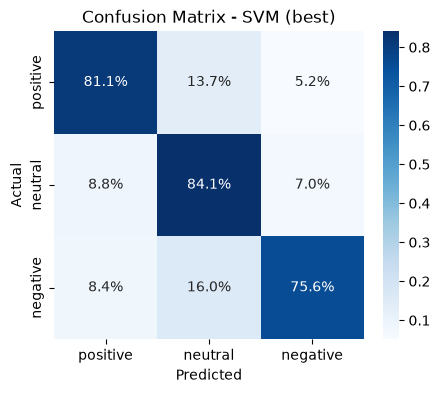

2026/07/19 17:16:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



SVM (Linear_SGD_epoch) — TEST RESULTS
              precision    recall  f1-score   support

    positive       0.84      0.81      0.82       503
     neutral       0.76      0.84      0.80       511
    negative       0.83      0.76      0.79       405

    accuracy                           0.81      1419
   macro avg       0.81      0.80      0.81      1419
weighted avg       0.81      0.81      0.81      1419



In [11]:
test_preds = final_model.predict(X_test)
test_metrics = evaluate(y_test, test_preds)

with mlflow.start_run(run_name=f"{MODEL_NAME}_BEST_{final_variant}"):
    if final_variant == "Linear_SGD_epoch":
        mlflow.log_params({
            "variant": final_variant, "C": best_params["C"], "class_weight": best_params["class_weight"],
            "alpha": sgd_alpha, "best_epoch": best_epoch,
        })
    elif final_variant.startswith("Kernel"):
        mlflow.log_params({"variant": final_variant, **kernel_search.best_params_})
    else:
        mlflow.log_params({"variant": final_variant, **random_search.best_params_})
    mlflow.log_param("tfidf_max_features", TFIDF_MAX_FEATURES)
    mlflow.log_param("tfidf_ngram_range", str(TFIDF_NGRAM_RANGE))
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("search_time_seconds", round(search_time + kernel_search_time, 2))

    cm_path = plot_confusion_matrix(y_test, test_preds, f"{MODEL_NAME} (best)")
    mlflow.log_artifact(cm_path)
    mlflow.sklearn.log_model(final_model, "model")
    run_id = mlflow.active_run().info.run_id

print(f"\n{MODEL_NAME} ({final_variant}) — TEST RESULTS")
print(classification_report(y_test, test_preds, target_names=["positive", "neutral", "negative"]))

with open(f"{MODELS_DIR}/{MODEL_NAME.lower()}_best.pkl", "wb") as f:
    pickle.dump({"vectorizer": vectorizer, "model": final_model, "variant": final_variant}, f)

## Register the best model in the MLflow Model Registry

In [12]:
client = MlflowClient()
try:
    registered = mlflow.register_model(model_uri=f"runs:/{run_id}/model", name=f"{MODEL_NAME}_Classifier")
    print(f"Registered '{MODEL_NAME}_Classifier' version {registered.version}")
except Exception as e:
    print(f"Registration skipped/failed: {e}")

print(f"\nBest {MODEL_NAME} test F1 (weighted): {test_metrics['f1_weighted']:.4f}")

Registered model 'SVM_Classifier' already exists. Creating a new version of this model...
2026/07/19 17:16:39 WARNING mlflow.tracking._model_registry.fluent: Run with id d9d7ef871fbe4fbea30c83d69218fa44 has no artifacts at artifact path 'model', registering model based on models:/m-1bf2eb17cc7246e698de89d98779e4ed instead


Registered 'SVM_Classifier' version 4

Best SVM test F1 (weighted): 0.8062


Created version '4' of model 'SVM_Classifier'.
